In [2]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import dataset
from sklearn.datasets import load_breast_cancer

# Import functions for splitting and hyperparameter tuning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

# Import preprocessing and machine learning model
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [3]:
# Load breast cancer dataset
data = load_breast_cancer()

# Separate input features and target labels
X = data.data
y = data.target

# Display dataset information
print("Dataset Shape:", X.shape)
print("Target Classes:", data.target_names)

Dataset Shape: (569, 30)
Target Classes: ['malignant' 'benign']


In [4]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% testing and 80% training
    random_state=42,     # Ensure reproducibility
    stratify=y           # Maintain class distribution
)

# Display training and testing dimensions
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [5]:
# Create pipeline containing scaling and SVM model
pipeline = Pipeline([
    ("scaler", StandardScaler()), 
    ("svc", SVC(probability=True, random_state=42))  
])

In [6]:
# Train the baseline SVM model
pipeline.fit(X_train, y_train)

# Predict class labels for testing data
y_pred = pipeline.predict(X_test)

# Predict probabilities for positive class
y_prob = pipeline.predict_proba(X_test)[:, 1]

C:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [7]:
print("\nBASELINE MODEL EVALUATION")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


BASELINE MODEL EVALUATION
Accuracy: 0.9824561403508771
Precision: 0.9861111111111112
Recall: 0.9861111111111112
F1 Score: 0.9861111111111112
ROC-AUC: 0.9950396825396826

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [8]:
# Create 5-fold stratified cross validation
cv = StratifiedKFold(
    n_splits=5,          # Divide data into 5 folds
    shuffle=True,        # Shuffle data before splitting
    random_state=42
)

# Perform cross validation on training data
cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"   # Evaluate using accuracy
)

print("\nCROSS VALIDATION")
print("Fold Scores:", cv_scores)
print("Mean Accuracy:", cv_scores.mean())


CROSS VALIDATION
Fold Scores: [0.94505495 0.97802198 0.96703297 0.96703297 0.98901099]
Mean Accuracy: 0.9692307692307693


C:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_bas

In [9]:
# Define parameters to test
param_grid = {
    "svc__C": [0.1, 1, 10, 100],  # Regularization parameter
    "svc__gamma": ["scale", "auto", 0.01, 0.1],  # Kernel coefficient
    "svc__kernel": ["rbf", "linear"]  # Kernel types
}

# Create Grid Search object
grid_search = GridSearchCV(
    estimator=pipeline,       # SVM pipeline
    param_grid=param_grid,    # Parameters to search
    cv=cv,                    # 5-fold cross validation
    scoring="roc_auc",        # Evaluation metric
    n_jobs=-1                 # Use all available processors
)

# Perform grid search on training data
grid_search.fit(X_train, y_train)
print("\nGRID SEARCH RESULTS")
print("Best Parameters:", grid_search.best_params_)
print("Best CV ROC-AUC:", grid_search.best_score_)


GRID SEARCH RESULTS
Best Parameters: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Best CV ROC-AUC: 0.9963880288957689


C:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [11]:
# Define parameter distributions
param_dist = {
    "svc__C": [0.01, 0.1, 1, 5, 10, 50, 100],
    "svc__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
    "svc__kernel": ["rbf", "linear"]
}

# Create Randomized Search object
random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=15,
    cv=cv,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

# Train Random Search
random_search.fit(X_train, y_train)

# Display results
print("Best Parameters:", random_search.best_params_)
print("Best CV ROC-AUC:", random_search.best_score_)

Best Parameters: {'svc__kernel': 'linear', 'svc__gamma': 1, 'svc__C': 1}
Best CV ROC-AUC: 0.9947368421052631


C:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [12]:
# Store all three models in a dictionary
models = {
    "Baseline": pipeline,
    "Grid Search": grid_search.best_estimator_,
    "Random Search": random_search.best_estimator_
}
results = []

# Iterate through each model
for name, model in models.items():

    # Generate predictions
    predictions = model.predict(X_test)

    # Generate prediction probabilities
    probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)
print("\nFINAL MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))


FINAL MODEL COMPARISON
        Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
     Baseline    0.9825     0.9861  0.9861    0.9861   0.9950
  Grid Search    0.9825     0.9861  0.9861    0.9861   0.9977
Random Search    0.9737     0.9859  0.9722    0.9790   0.9964


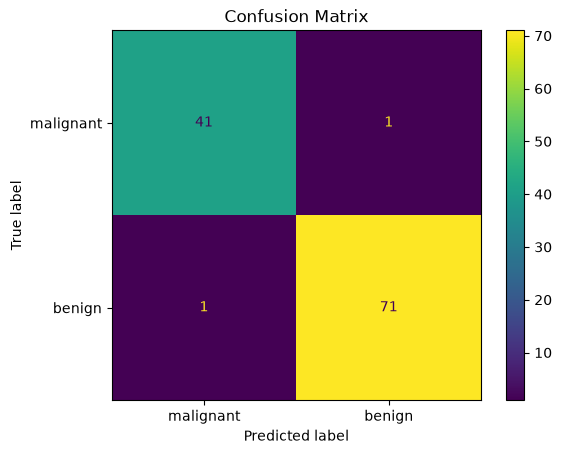

In [13]:
best_model = grid_search.best_estimator_

best_predictions = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=data.target_names
)

plt.title("Confusion Matrix")
plt.show()

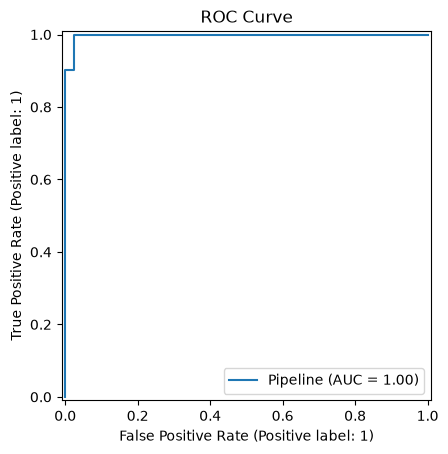

In [14]:
# Plot ROC curve for the best model
RocCurveDisplay.from_estimator(
    best_model,
    X_test,
    y_test
)

plt.title("ROC Curve")

# Display ROC curve
plt.show()